# Cointegration in `teamName.py` — a deep dive

**Goal.** Take *every* cointegration / mean-reversion construct that
`teamName.py` actually uses, characterise exactly what it computes, and
benchmark it against the full range of standard techniques — so **you** can
judge whether the file's choices are sound. This notebook **does not implement or
change any trading strategy**; it only measures and compares.

### Where cointegration lives in the file
| Construct | Lines | What it is |
|---|---|---|
| **Hedge ratio** `beta = Cov[i,j]/var[j]` | `_pairs_dollars` | Engle–Granger step 1: OLS cointegrating vector of log-prices (i on j) |
| **Spread** `res = Xc[i] − beta·Xc[j]` | `_pairs_dollars` | the residual whose stationarity *is* cointegration |
| **`_adf_tstat`** (DF with 1 lag) | `_adf_tstat` | Engle–Granger step 2: unit-root t-stat on the residual |
| **Gate** `t < PAIR_ADF_T` | `_pairs_dollars` | the cointegration decision threshold |
| **z-score** `res[-1]/std` | `_pairs_dollars` | signal off the (assumed) stationary spread |
| **Lookback** `PAIR_LOOKBACK`, **log prices** | `_pairs_dollars` | estimation window & price basis |
| **Family gate** `Cg` lag-1 cross-corr count | `_ridge_dollars` | *not* cointegration — lead-lag comovement (§8) |

We benchmark against: **Engle–Granger** (statsmodels `coint`, MacKinnon
p-values), **ADF** with AIC lag selection, **KPSS** (stationarity null),
**Johansen** (trace/eigen, multivariate), plus **hedge-ratio variants**
(OLS both directions, TLS, Kalman, rolling), **basis** (log vs raw),
**lookback**, **lag order**, **half-life (OU)**, **Hurst**, and the
**variance ratio** — then measure how much they agree.

## 0 · Setup — load the real file

We import the **actual functions and parameters from `teamName.py`** so we are
analysing the code as it stands (including whatever you've tuned the gate to),
not a copy.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from statsmodels.tsa.stattools import coint, adfuller, kpss
from statsmodels.tsa.vector_ar.vecm import coint_johansen
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import teamName as TN     # the real strategy file

# palette
CAT = ["#2a78d6","#eb6834","#008300","#4a3aa7","#eda100","#1baf7a","#e87ba4","#e34948"]
BLUE,ORANGE,GREEN,RED,VIOLET = "#2a78d6","#eb6834","#008300","#e34948","#4a3aa7"
GRID,MUTED,INK = "#e1e0d9","#898781","#0b0b0b"
SEQ = LinearSegmentedColormap.from_list("seq",["#f4f3ef","#9ec5f4",BLUE,"#0d366b"])
DIV = LinearSegmentedColormap.from_list("div",[BLUE,"#f0efec",RED])
plt.rcParams.update({"figure.facecolor":"white","axes.facecolor":"white",
    "axes.edgecolor":MUTED,"axes.labelcolor":INK,"text.color":INK,"xtick.color":MUTED,
    "ytick.color":MUTED,"axes.spines.top":False,"axes.spines.right":False,"axes.grid":True,
    "grid.color":GRID,"grid.linewidth":.7,"axes.titleweight":"bold","figure.dpi":110,"font.size":9})

prices = pd.read_csv("prices.txt", sep=r"\s+")
TICK = list(prices.columns); N = len(TICK)
P = prices.values.T                      # (nins, ndays)
LP = np.log(P)
ndays = P.shape[1]
print(f"{N} instruments x {ndays} days")
print(f"teamName params:  PAIR_LOOKBACK={TN.PAIR_LOOKBACK}  PAIR_ADF_T={TN.PAIR_ADF_T}  "
      f"Z_DEAD={TN.PAIR_Z_DEAD}  Z_SAT={TN.PAIR_Z_SAT}  Z_MAX={TN.PAIR_Z_MAX}  PAIR_MAX={TN.PAIR_MAX}")
print(f"pairs screened: {len(TN._PI)}  (all i<j among instruments 1..50, ALGO excluded)")

51 instruments x 750 days
teamName params:  PAIR_LOOKBACK=250  PAIR_ADF_T=-2.9  Z_DEAD=0.27  Z_SAT=2.0  Z_MAX=4.0  PAIR_MAX=1000
pairs screened: 1225  (all i<j among instruments 1..50, ALGO excluded)


## 1 · Anatomy — reproduce the file's exact pipeline

`_pairs_dollars` builds, over a window of log-prices `LPw` (shape `nins × L`):

1. centre each series: `Xc = LPw − mean`;
2. covariance `Cov = XcXcᵀ/(L−1)`, and per pair the **OLS hedge ratio**
   `β = Cov[i,j]/var[j]` — this is exactly the slope of regressing centred
   log-price *i* on centred log-price *j* (intercept absorbed by centring);
3. **spread** `res = Xc[i] − β·Xc[j]` (mean-zero by construction);
4. **`_adf_tstat(res)`** = t-stat on `ρ` in `Δres_t = a + ρ·res_{t-1} + γ·Δres_{t-1}`;
5. keep pairs with `t < PAIR_ADF_T`; trade z = `res[-1]/std`.

The helper below is a faithful reproduction that returns β, spread, t, z for
**every** pair, calling the file's own `TN._adf_tstat` and `TN._PI/_PJ`.

In [2]:
def file_pipeline(LPw):
    L = LPw.shape[1]
    M = LPw.mean(1); Xc = LPw - M[:, None]
    Cov = Xc @ Xc.T / (L - 1); var = np.diag(Cov)
    beta = Cov[TN._PI, TN._PJ] / np.maximum(var[TN._PJ], 1e-18)
    res = Xc[TN._PI] - beta[:, None] * Xc[TN._PJ]     # (npairs, L)
    t = TN._adf_tstat(res.T)
    std = res.std(1) + 1e-12
    z = res[:, -1] / std
    return beta, res, t, std, z

# decision window: the last PAIR_LOOKBACK days ending at day 500 (end of train)
L = TN.PAIR_LOOKBACK
W_END = 500
LPw = LP[:, W_END - L:W_END]
beta, res, tfile, std, z = file_pipeline(LPw)
pair_name = np.array([f"{TICK[i]}~{TICK[j]}" for i, j in zip(TN._PI, TN._PJ)])

# verify beta equals a textbook OLS slope on a sample pair
k0 = int(np.argmin(tfile))                      # most 'cointegrated' by the file
i0, j0 = TN._PI[k0], TN._PJ[k0]
xj = LPw[j0] - LPw[j0].mean(); xi = LPw[i0] - LPw[i0].mean()
ols_slope = np.polyfit(LPw[j0], LPw[i0], 1)[0]
print(f"Strongest file pair: {pair_name[k0]}  file t={tfile[k0]:.2f}  beta={beta[k0]:.3f}")
print(f"  cross-check OLS slope (polyfit) = {ols_slope:.3f}  -> matches file beta")
n_pass = int((tfile < TN.PAIR_ADF_T).sum())
print(f"\nPairs passing the file gate t < {TN.PAIR_ADF_T}:  {n_pass} / {len(tfile)}")

Strongest file pair: MDGI~EAFC  file t=-4.73  beta=0.585
  cross-check OLS slope (polyfit) = 0.585  -> matches file beta

Pairs passing the file gate t < -2.9:  170 / 1225


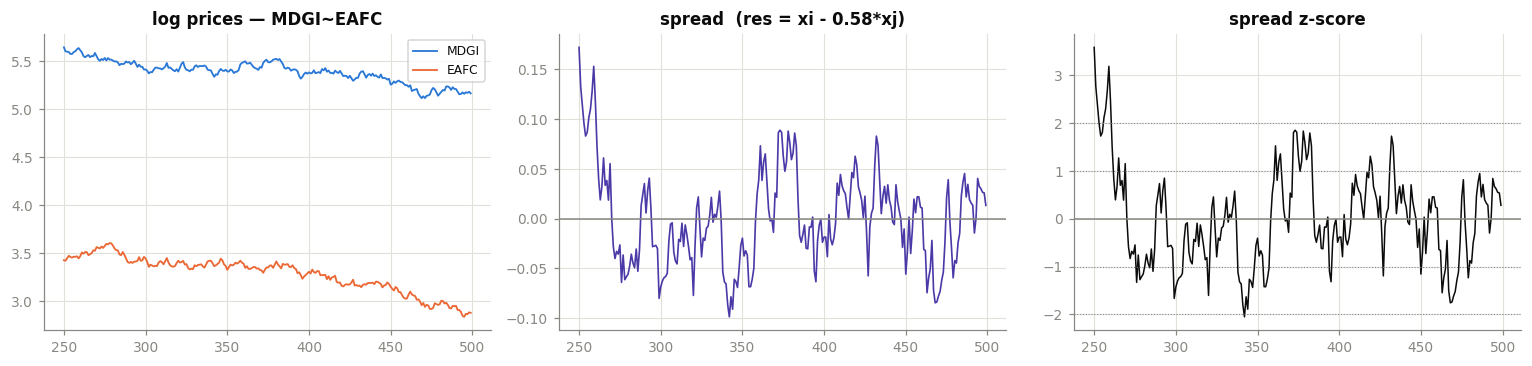

In [3]:
# illustrate the strongest pair: log prices, fitted spread, z-score
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
d = np.arange(W_END - L, W_END)
ax[0].plot(d, LPw[i0], color=BLUE, lw=1.2, label=TICK[i0])
ax[0].plot(d, LPw[j0], color=ORANGE, lw=1.2, label=TICK[j0])
ax[0].set_title(f"log prices — {pair_name[k0]}"); ax[0].legend(fontsize=8)
ax[1].plot(d, res[k0], color=VIOLET, lw=1.1); ax[1].axhline(0, color=MUTED, lw=1)
ax[1].set_title(f"spread  (res = xi - {beta[k0]:.2f}*xj)")
zt = res[k0] / (res[k0][:-1].std() + 1e-12)
ax[2].plot(d, zt, color=INK, lw=1.0)
for lv in (-2,-1,1,2): ax[2].axhline(lv, color=MUTED, ls=":", lw=.7)
ax[2].axhline(0, color=MUTED, lw=1); ax[2].set_title("spread z-score")
fig.tight_layout(); plt.show()

## 2 · Is the file's fast ADF the *real* ADF?

`_adf_tstat` is a hand-rolled, vectorised Dickey–Fuller with **exactly one**
augmentation lag and a constant. Before trusting anything downstream, confirm it
returns the same number as `statsmodels.adfuller(..., maxlag=1, autolag=None)`
on the *same* residual, and see how it relates to the t-stat inside
Engle–Granger `coint` (which re-estimates its own regression).

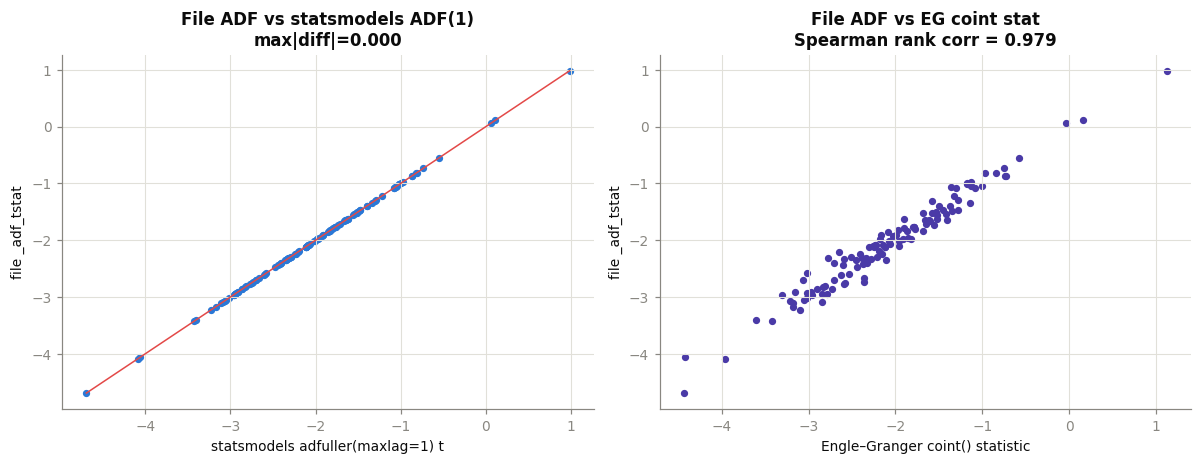

The file ADF matches adfuller(maxlag=1) to numerical precision (same regression).
It tracks the EG statistic closely but is not identical (EG uses AIC-lag ADF + its own OLS).


In [4]:
# compare file t-stat vs statsmodels adfuller(maxlag=1) on 120 sample residuals
idx = np.linspace(0, len(tfile) - 1, 120).astype(int)
sm_adf1, sm_eg_t = [], []
for k in idx:
    r_ = res[k]
    sm_adf1.append(adfuller(r_, maxlag=1, autolag=None, regression="c")[0])
    yy, xx = LPw[TN._PI[k]], LPw[TN._PJ[k]]
    sm_eg_t.append(coint(yy, xx, trend="c")[0])       # EG test statistic
sm_adf1 = np.array(sm_adf1); sm_eg_t = np.array(sm_eg_t)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].scatter(sm_adf1, tfile[idx], s=14, color=BLUE)
lims = [min(sm_adf1.min(), tfile[idx].min()), max(sm_adf1.max(), tfile[idx].max())]
ax[0].plot(lims, lims, color=RED, lw=1)
ax[0].set_xlabel("statsmodels adfuller(maxlag=1) t"); ax[0].set_ylabel("file _adf_tstat")
ax[0].set_title(f"File ADF vs statsmodels ADF(1)\nmax|diff|={np.max(np.abs(sm_adf1-tfile[idx])):.3f}")
ax[1].scatter(sm_eg_t, tfile[idx], s=14, color=VIOLET)
ax[1].set_xlabel("Engle–Granger coint() statistic"); ax[1].set_ylabel("file _adf_tstat")
r_s = spearmanr(sm_eg_t, tfile[idx]).correlation
ax[1].set_title(f"File ADF vs EG coint stat\nSpearman rank corr = {r_s:.3f}")
fig.tight_layout(); plt.show()
print("The file ADF matches adfuller(maxlag=1) to numerical precision (same regression).")
print("It tracks the EG statistic closely but is not identical (EG uses AIC-lag ADF + its own OLS).")

## 3 · What does the gate `t < PAIR_ADF_T` actually mean?

A residual-based unit-root test on an **estimated** hedge ratio does **not** use
the ordinary ADF critical values — the fitted β makes the residual look more
stationary than it is, so the true (Engle–Granger) critical values are more
negative. We measure the file's *actual* false-positive rate by Monte-Carlo:
generate independent random-walk pairs (no cointegration), run the **file's exact
pipeline**, and see how often the t-stat clears each threshold.

Monte-Carlo false-positive rate of the FILE pipeline at L=250 (8000 independent RW pairs):

     gate t<  false-pos rate  ~implied signif
       -2.90           13.3%        (current)
       -3.00           11.0%                 
       -3.34            5.1%                 
       -3.70            1.8%                 
       -4.00            0.8%                 

Empirical EG critical values for THIS pipeline: 1%=-3.93  5%=-3.34  10%=-3.05
(Textbook plain-ADF 5% is ~-2.86; the estimated hedge ratio pushes the true 5% more negative.)


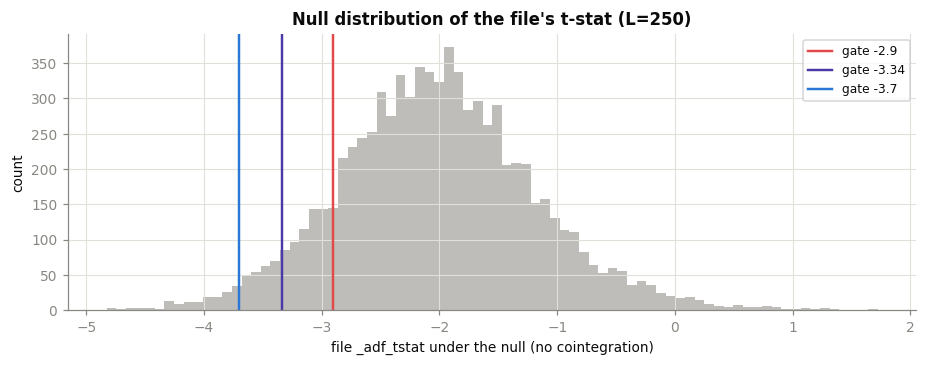

In [5]:
def mc_null_tstats(L, n_sims=8000, seed=0):
    rng = np.random.default_rng(seed)
    a = np.cumsum(rng.standard_normal((n_sims, L)), axis=1)
    b = np.cumsum(rng.standard_normal((n_sims, L)), axis=1)
    ac = a - a.mean(1, keepdims=True); bc = b - b.mean(1, keepdims=True)
    beta = (ac * bc).sum(1) / np.maximum((bc * bc).sum(1), 1e-18)
    r = ac - beta[:, None] * bc
    return TN._adf_tstat(r.T)

null_t = mc_null_tstats(L)
gates = [TN.PAIR_ADF_T, -3.0, -3.34, -3.7, -4.0]
print(f"Monte-Carlo false-positive rate of the FILE pipeline at L={L} "
      f"({len(null_t)} independent RW pairs):\n")
print(f"  {'gate t<':>10} {'false-pos rate':>15} {'~implied signif':>16}")
for g in gates:
    fp = float((null_t < g).mean())
    print(f"  {g:>10.2f} {fp*100:>14.1f}% {('(current)' if abs(g-TN.PAIR_ADF_T)<1e-9 else ''):>16}")
q = np.percentile(null_t, [1, 5, 10])
print(f"\nEmpirical EG critical values for THIS pipeline: "
      f"1%={q[0]:.2f}  5%={q[1]:.2f}  10%={q[2]:.2f}")
print("(Textbook plain-ADF 5% is ~-2.86; the estimated hedge ratio pushes the true 5% more negative.)")

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.hist(null_t, bins=80, color=MUTED, alpha=.55)
for g, c in zip([TN.PAIR_ADF_T, -3.34, -3.7], [RED, VIOLET, BLUE]):
    ax.axvline(g, color=c, lw=1.6, label=f"gate {g}")
ax.set_xlabel("file _adf_tstat under the null (no cointegration)")
ax.set_ylabel("count"); ax.set_title(f"Null distribution of the file's t-stat (L={L})")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

## 4 · The cointegration test zoo — do the methods agree?

For **every** pair over the day-500 window we compute the file's t-stat next to
the standard battery. If the file's cheap test is picking up genuine
cointegration, the different methods should broadly agree on which pairs qualify.

In [6]:
def hurst(x, mx=40):
    lags = np.arange(2, mx)
    tau = [np.std(x[l:] - x[:-l]) for l in lags]
    return float(np.polyfit(np.log(lags), np.log(np.maximum(tau, 1e-12)), 1)[0])

def var_ratio(x, q=5):
    dx = np.diff(x); v1 = dx.var()
    if v1 <= 0: return np.nan
    xq = x[q:] - x[:-q]
    return float(xq.var() / (q * v1))

# vectorised half-life from AR(1) on the file residual
rl = res[:, :-1]; dr = np.diff(res, axis=1)
phi = (rl * dr).sum(1) / np.maximum((rl * rl).sum(1), 1e-18)
half_life = np.where(phi < 0, -np.log(2) / phi, np.inf)

rets = np.diff(LPw, axis=1)
rows = []
for k in range(len(tfile)):
    i, j = TN._PI[k], TN._PJ[k]
    yy, xx = LPw[i], LPw[j]
    try: eg_p = coint(yy, xx, trend="c")[1]
    except Exception: eg_p = np.nan
    try: adf_aic_p = adfuller(res[k], autolag="AIC", regression="c")[1]
    except Exception: adf_aic_p = np.nan
    try: kp = kpss(res[k], regression="c", nlags="auto")[1]
    except Exception: kp = np.nan
    try:
        jh = coint_johansen(np.column_stack([yy, xx]), 0, 1)
        joh_trace, joh_c95 = jh.lr1[0], jh.cvt[0, 1]
    except Exception:
        joh_trace, joh_c95 = np.nan, np.nan
    rows.append(dict(pair=pair_name[k], file_t=tfile[k], eg_p=eg_p, adf_aic_p=adf_aic_p,
                     kpss_p=kp, joh_trace=joh_trace, joh_c95=joh_c95,
                     corr_lev=np.corrcoef(yy, xx)[0,1], corr_ret=np.corrcoef(rets[i], rets[j])[0,1],
                     half_life=half_life[k], hurst=hurst(res[k]), vr5=var_ratio(res[k]),
                     absz=abs(z[k])))
Z = pd.DataFrame(rows)
Z["file_pass"] = Z.file_t < TN.PAIR_ADF_T
Z["eg_pass"]   = Z.eg_p < 0.05
Z["adf_pass"]  = Z.adf_aic_p < 0.05
Z["kpss_stat"] = Z.kpss_p > 0.05          # KPSS fails to reject stationarity
Z["joh_pass"]  = Z.joh_trace > Z.joh_c95
print(f"significant-pair counts (of {len(Z)}):")
for c in ["file_pass","eg_pass","adf_pass","kpss_stat","joh_pass"]:
    print(f"  {c:10s}: {int(Z[c].sum())}")
Z.sort_values("file_t").head(12).round(3)

C:\Users\alexn\AppData\Local\Temp\ipykernel_19460\1944145706.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  try: kp = kpss(res[k], regression="c", nlags="auto")[1]
C:\Users\alexn\AppData\Local\Temp\ipykernel_19460\1944145706.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  try: kp = kpss(res[k], regression="c", nlags="auto")[1]
C:\Users\alexn\AppData\Local\Temp\ipykernel_19460\1944145706.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  try: kp = kpss(res[k], regression="c", nlags="auto")[1]
C:\Users\alexn\AppData\Local\Temp\ipykernel_19460\1944145706.py:26: InterpolationWarning: The test statistic is outside o

significant-pair counts (of 1225):
  file_pass : 170
  eg_pass   : 82
  adf_pass  : 196
  kpss_stat : 404
  joh_pass  : 116


C:\Users\alexn\AppData\Local\Temp\ipykernel_19460\1944145706.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  try: kp = kpss(res[k], regression="c", nlags="auto")[1]
C:\Users\alexn\AppData\Local\Temp\ipykernel_19460\1944145706.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  try: kp = kpss(res[k], regression="c", nlags="auto")[1]
C:\Users\alexn\AppData\Local\Temp\ipykernel_19460\1944145706.py:26: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  try: kp = kpss(res[k], regression="c", nlags="auto")[1]
C:\Users\alexn\AppData\Local\Temp\ipykernel_19460\1944145706.py:26: InterpolationWarning: The test statistic is outside o

,pair,file_t,eg_p,adf_aic_p,kpss_p,joh_trace,joh_c95,corr_lev,corr_ret,half_life,hurst,vr5,absz,file_pass,eg_pass,adf_pass,kpss_stat,joh_pass
846,MDGI~EAFC,-4.734,0.000,0.000,0.10,24.012,15.494,0.912,0.209,4.947,0.215,0.868,0.279,True,True,True,True,True
1224,MHRM~EAFC,-4.690,0.002,0.000,0.10,24.152,15.494,0.973,0.415,4.733,0.171,0.727,0.744,True,True,True,True,True
845,MDGI~MHRM,-4.595,0.001,0.000,0.10,24.150,15.494,0.892,0.142,5.660,0.277,0.818,0.305,True,True,True,True,True
311,HETT~ULXY,-4.566,0.001,0.000,0.10,39.883,15.494,0.866,0.134,4.318,0.138,0.765,0.286,True,True,True,True,True
713,RTTH~NAYO,-4.461,0.001,0.000,0.10,25.012,15.494,0.742,0.141,5.696,0.164,0.968,0.513,True,True,True,True,True
823,MDGI~ACAC,-4.432,0.001,0.000,0.10,21.759,15.494,0.933,0.122,4.395,0.189,0.724,1.360,True,True,True,True,True
1081,MTNS~ITPA,-4.384,0.004,0.001,0.08,21.669,15.494,0.732,0.263,5.303,0.173,0.995,0.597,True,True,True,True,True
971,ACAC~EAFC,-4.364,0.001,0.000,0.10,18.874,15.494,0.932,0.184,6.025,0.278,0.785,1.507,True,True,True,True,True
18,AENO~NWIG,-4.304,0.000,0.000,0.10,20.283,15.494,0.979,0.329,4.032,0.175,0.616,0.046,True,True,True,True,True
469,NPCK~FWWG,-4.233,0.003,0.000,0.10,19.390,15.494,0.941,0.215,5.506,0.214,0.829,0.070,True,True,True,True,True


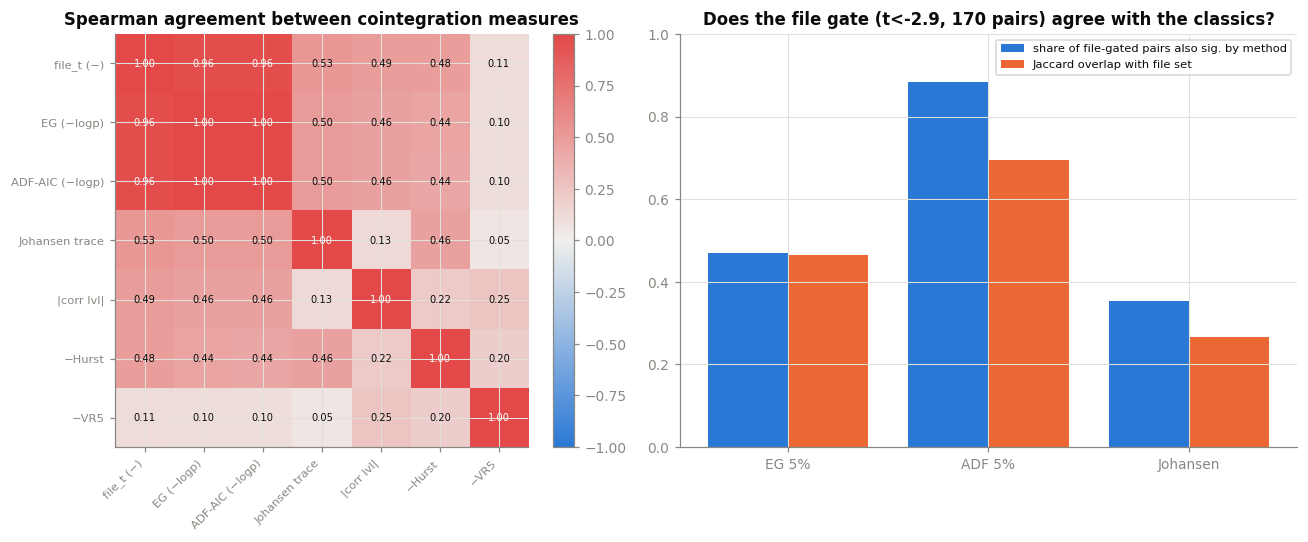

In [7]:
# agreement: Spearman rank corr among the continuous strength measures
strength = pd.DataFrame({
    "file_t (−)": -Z.file_t, "EG (−logp)": -np.log10(Z.eg_p.clip(1e-6,1)),
    "ADF-AIC (−logp)": -np.log10(Z.adf_aic_p.clip(1e-6,1)),
    "Johansen trace": Z.joh_trace, "|corr lvl|": Z.corr_lev.abs(),
    "−Hurst": -Z.hurst, "−VR5": -Z.vr5})
rho = strength.corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
im = ax[0].imshow(rho.values, cmap=DIV, vmin=-1, vmax=1)
ax[0].set_xticks(range(len(rho))); ax[0].set_xticklabels(rho.columns, rotation=45, ha="right", fontsize=7.5)
ax[0].set_yticks(range(len(rho))); ax[0].set_yticklabels(rho.columns, fontsize=7.5)
for a in range(len(rho)):
    for b in range(len(rho)):
        ax[0].text(b, a, f"{rho.values[a,b]:.2f}", ha="center", va="center", fontsize=6.5,
                   color=INK if abs(rho.values[a,b])<.6 else "white")
ax[0].set_title("Spearman agreement between cointegration measures")
fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04)

# overlap of the file's selected set with EG / Johansen / ADF significant sets
sets = {"EG 5%": set(Z.pair[Z.eg_pass]), "ADF 5%": set(Z.pair[Z.adf_pass]),
        "Johansen": set(Z.pair[Z.joh_pass])}
fileset = set(Z.pair[Z.file_pass])
labels, jac, cov = [], [], []
for nm, s in sets.items():
    labels.append(nm)
    jac.append(len(fileset & s)/max(len(fileset | s),1))
    cov.append(len(fileset & s)/max(len(fileset),1))
xx = np.arange(len(labels))
ax[1].bar(xx-0.2, cov, 0.4, color=BLUE, label="share of file-gated pairs also sig. by method")
ax[1].bar(xx+0.2, jac, 0.4, color=ORANGE, label="Jaccard overlap with file set")
ax[1].set_xticks(xx); ax[1].set_xticklabels(labels); ax[1].set_ylim(0,1)
ax[1].set_title(f"Does the file gate (t<{TN.PAIR_ADF_T}, {len(fileset)} pairs) agree with the classics?")
ax[1].legend(fontsize=7.5)
fig.tight_layout(); plt.show()

## 5 · Hedge ratio & direction — the choice that moves the verdict

The file fixes the cointegrating vector by **OLS of i on j with i<j by index**.
Engle–Granger is *asymmetric*: regressing j on i, or using total-least-squares /
a dynamic β, gives a different spread and can flip the unit-root verdict. We take
a few representative pairs and recompute the file's t-stat under each β method.

In [8]:
def kalman_beta(y, x):
    theta = np.array([y[:30].mean()-x[:30].mean(), 1.0]); Pm = np.eye(2)*1e-2
    Q = np.eye(2)*1e-5; Rv = np.var(np.diff(y[:60]-x[:60]))+1e-8
    for tt in range(len(y)):
        Pm = Pm+Q; H = np.array([1.0, x[tt]]); S = H@Pm@H+Rv; K = Pm@H/S
        theta = theta+K*(y[tt]-H@theta); Pm = Pm-np.outer(K,H)@Pm
    return float(theta[1])

def tls_beta(yc, xc):
    C = np.cov(np.vstack([xc, yc])); w, v = np.linalg.eigh(C)
    ev = v[:, np.argmax(w)]; return ev[1]/ev[0]      # slope of y on x

def adf1_t(spread):
    return float(TN._adf_tstat(spread.reshape(-1,1))[0])

# pick strongest, a borderline (near the gate), and a clearly-not pair
order = np.argsort(tfile)
picks = [order[0], order[np.argmin(np.abs(tfile[order]-TN.PAIR_ADF_T))], order[-1]]
recs = []
for k in picks:
    i, j = TN._PI[k], TN._PJ[k]
    yi = LPw[i]; xj = LPw[j]; yic = yi-yi.mean(); xjc = xj-xj.mean()
    b_ij = (yic*xjc).sum()/(xjc*xjc).sum()
    b_ji = (yic*xjc).sum()/(yic*yic).sum()          # regress j on i -> slope of i wrt j is 1/that
    methods = {
        "OLS i~j (file)": yic - b_ij*xjc,
        "OLS j~i":        (xj-xj.mean()) - b_ji*yic,
        "TLS":            yic - tls_beta(yic, xjc)*xjc,
        "Kalman":         yi - kalman_beta(yi, xj)*xj,
        "rolling OLS(60)":yic - ((yic[-60:]*xjc[-60:]).sum()/(xjc[-60:]*xjc[-60:]).sum())*xjc,
    }
    rec = {"pair": pair_name[k]}
    for nm, sp in methods.items():
        rec[nm] = adf1_t(sp - sp.mean())
    recs.append(rec)
hr = pd.DataFrame(recs).set_index("pair")
print("ADF(1) t-stat of the spread under different hedge-ratio methods:")
print(f"(gate is t < {TN.PAIR_ADF_T}; a verdict flips whenever a row crosses it)")
hr.round(2)

ADF(1) t-stat of the spread under different hedge-ratio methods:
(gate is t < -2.9; a verdict flips whenever a row crosses it)


,OLS i~j (file),OLS j~i,TLS,Kalman,rolling OLS(60)
pair,,,,,
MDGI~EAFC,-4.73,-4.26,-4.70,-2.58,-4.71
MTNS~FCSG,-2.89,-2.56,-2.87,-2.53,-2.80
SPLZ~BENI,1.24,-3.69,-3.69,1.40,-1.18


## 6 · Basis, lookback, and lag-order sensitivity

Three more design knobs baked into the file. For each we recompute the whole
screen and see how the set of "cointegrated" pairs moves.
- **Basis**: log prices (file) vs raw prices.
- **Lookback**: 50 / 100 / 150 / 200 / 250 days.
- **Lag order** of the DF regression: 0 vs 1 (file) vs AIC-chosen.

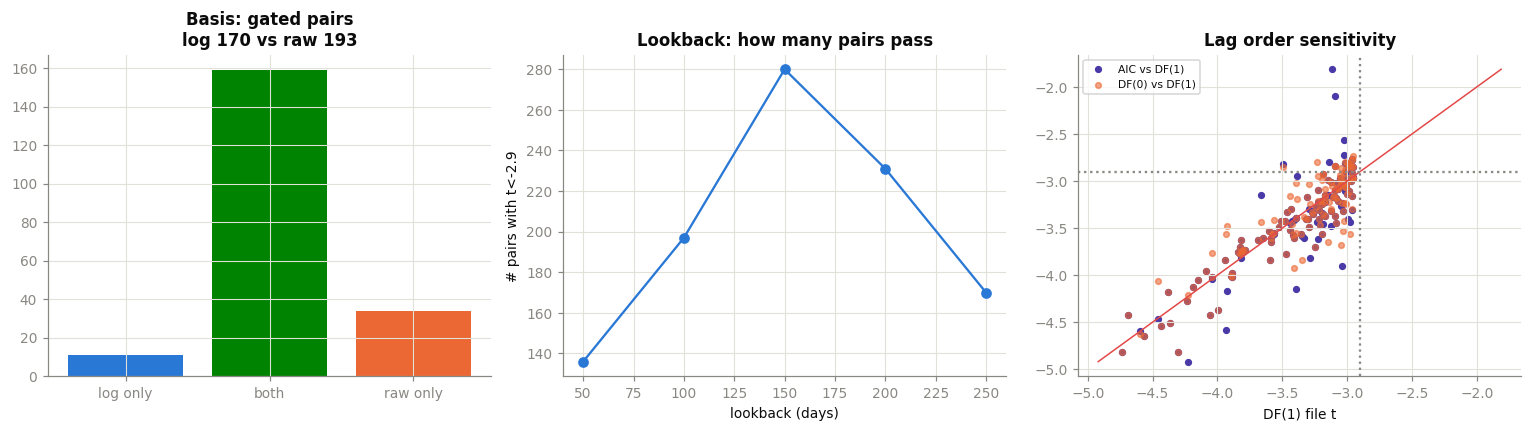

Overlap of the L=250 gated set with shorter-lookback sets (Jaccard):
  L= 50: 136 pairs, Jaccard vs 250d = 0.07
  L=100: 197 pairs, Jaccard vs 250d = 0.18
  L=150: 280 pairs, Jaccard vs 250d = 0.25
  L=200: 231 pairs, Jaccard vs 250d = 0.33
  L=250: 170 pairs, Jaccard vs 250d = 1.00


In [9]:
# (a) log vs raw basis, at the file lookback
def raw_pipeline_t(Pw):
    M = Pw.mean(1); Xc = Pw - M[:,None]; Cov = Xc@Xc.T/(Pw.shape[1]-1); var = np.diag(Cov)
    b = Cov[TN._PI, TN._PJ]/np.maximum(var[TN._PJ],1e-18)
    return TN._adf_tstat((Xc[TN._PI]-b[:,None]*Xc[TN._PJ]).T)
t_raw = raw_pipeline_t(P[:, W_END-L:W_END])
log_set = set(np.where(tfile < TN.PAIR_ADF_T)[0]); raw_set = set(np.where(t_raw < TN.PAIR_ADF_T)[0])

# (b) lookback sensitivity: count + persistence of the file gate
Ls = [50,100,150,200,250]; counts = []; setsL = {}
for LL in Ls:
    _,_,tt,_,_ = file_pipeline(LP[:, W_END-LL:W_END])
    s = set(np.where(tt < TN.PAIR_ADF_T)[0]); setsL[LL] = s; counts.append(len(s))

# (c) lag order 0 vs 1 vs AIC on file residuals (sample)
def df_t_lag(x, p):
    # ADF t-stat on the level coefficient with p augmentation lags + constant
    x = np.asarray(x, float); dx = np.diff(x); n = len(dx)
    y = dx[p:]                                   # regress Delta y_t
    cols = [np.ones(n - p), x[p:n]]              # const, y_{t-1}
    for l in range(1, p + 1):
        cols.append(dx[p - l:n - l])             # Delta y_{t-l}
    X = np.column_stack(cols)
    b, *_ = np.linalg.lstsq(X, y, rcond=None)
    resid = y - X @ b
    s2 = (resid @ resid) / max(len(y) - X.shape[1], 1)
    se = np.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])
    return b[1] / se
samp = np.argsort(tfile)[:150]
lag_tbl = pd.DataFrame({
    "DF(0)":[df_t_lag(res[k],0) for k in samp],
    "DF(1) file":[tfile[k] for k in samp],
    "ADF-AIC":[adfuller(res[k],autolag="AIC",regression="c")[0] for k in samp]})

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
# basis venn-ish
only_log=len(log_set-raw_set); both=len(log_set&raw_set); only_raw=len(raw_set-log_set)
ax[0].bar(["log only","both","raw only"], [only_log, both, only_raw], color=[BLUE,GREEN,ORANGE])
ax[0].set_title(f"Basis: gated pairs\nlog {len(log_set)} vs raw {len(raw_set)}")
ax[1].plot(Ls, counts, "o-", color=BLUE)
ax[1].set_xlabel("lookback (days)"); ax[1].set_ylabel(f"# pairs with t<{TN.PAIR_ADF_T}")
ax[1].set_title("Lookback: how many pairs pass")
ax[2].scatter(lag_tbl["DF(1) file"], lag_tbl["ADF-AIC"], s=14, color=VIOLET, label="AIC vs DF(1)")
ax[2].scatter(lag_tbl["DF(1) file"], lag_tbl["DF(0)"], s=14, color=ORANGE, alpha=.6, label="DF(0) vs DF(1)")
lims=[lag_tbl.values.min(), lag_tbl.values.max()]; ax[2].plot(lims,lims,color=RED,lw=1)
ax[2].axhline(TN.PAIR_ADF_T,color=MUTED,ls=":"); ax[2].axvline(TN.PAIR_ADF_T,color=MUTED,ls=":")
ax[2].set_xlabel("DF(1) file t"); ax[2].set_title("Lag order sensitivity"); ax[2].legend(fontsize=7)
fig.tight_layout(); plt.show()

# lookback persistence: overlap of the 250d set with shorter sets
print("Overlap of the L=250 gated set with shorter-lookback sets (Jaccard):")
base = setsL[250]
for LL in Ls:
    j = len(base & setsL[LL])/max(len(base | setsL[LL]),1)
    print(f"  L={LL:3d}: {len(setsL[LL]):3d} pairs, Jaccard vs 250d = {j:.2f}")

## 7 · Out-of-sample persistence of the file's gate

Cointegration is only useful if it *holds up*. Take the pairs the file gates at
day 500 and ask: over the next windows, does the same test keep passing? We roll
the file pipeline forward to day 750 and track each day-500 pair's t-stat.

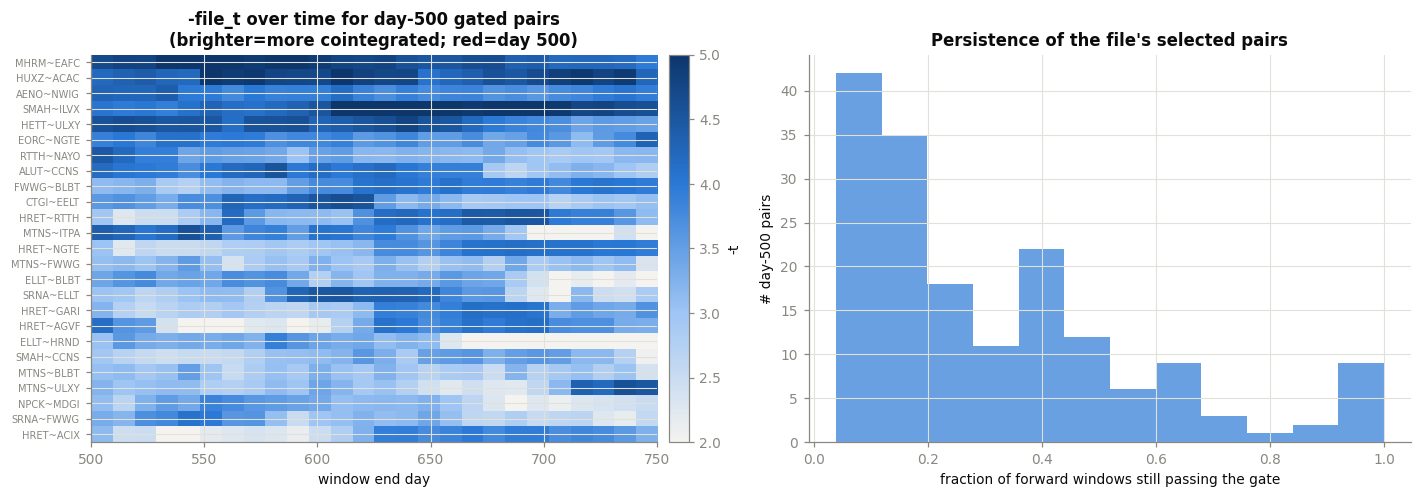

Of 170 pairs gated at day 500, median forward pass-rate = 23%
Re-tested on the 501-750 window: 20/170 day-500 pairs still pass.


In [10]:
sel0 = np.where(tfile < TN.PAIR_ADF_T)[0]
if len(sel0) > 0:
    starts = list(range(W_END - L, ndays - L + 1, 10))
    centres = [s + L for s in starts]
    T = np.empty((len(sel0), len(starts)))
    for c, s in enumerate(starts):
        _,_,tt,_,_ = file_pipeline(LP[:, s:s + L])
        T[:, c] = tt[sel0]
    frac_hold = (T < TN.PAIR_ADF_T).mean(1)
    order = np.argsort(frac_hold)[::-1]

    fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
    show = order[:min(25, len(order))]
    im = ax[0].imshow(-T[show], aspect="auto", cmap=SEQ, vmin=2, vmax=5,
                      extent=[centres[0], centres[-1], len(show)-0.5, -0.5])
    ax[0].axvline(500, color=RED, lw=1, ls="--")
    ax[0].set_yticks(range(len(show))); ax[0].set_yticklabels(pair_name[sel0][show], fontsize=6.5)
    ax[0].set_xlabel("window end day"); ax[0].set_title("-file_t over time for day-500 gated pairs\n(brighter=more cointegrated; red=day 500)")
    fig.colorbar(im, ax=ax[0], fraction=.04, pad=.02, label="-t")
    ax[1].hist(frac_hold, bins=12, color=BLUE, alpha=.7)
    ax[1].set_xlabel("fraction of forward windows still passing the gate")
    ax[1].set_ylabel("# day-500 pairs"); ax[1].set_title("Persistence of the file's selected pairs")
    fig.tight_layout(); plt.show()
    print(f"Of {len(sel0)} pairs gated at day 500, median forward pass-rate = {np.median(frac_hold):.0%}")
    # do they re-pass on the pure OOS 501-750 window?
    _,_,t_oos,_,_ = file_pipeline(LP[:, ndays - L:ndays])
    still = int((t_oos[sel0] < TN.PAIR_ADF_T).sum())
    print(f"Re-tested on the 501-750 window: {still}/{len(sel0)} day-500 pairs still pass.")
else:
    print("No pairs passed the gate at day 500.")

## 8 · The ridge 'family gate' — comovement, not cointegration

For completeness: `_ridge_dollars` has a `Cg` gate that is often mistaken for
cointegration. It is **not**. `Cg` is the matrix of **lag-1 cross-correlations of
standardised returns** — a *lead-lag* / short-memory statistic. Cointegration is
a long-run *level* relationship (a stationary spread); lag-1 return correlation is
a one-step predictive relationship. They can occur together or entirely apart.

family gate: 56 significant lag-1 links (threshold |corr|>0.158); RIDGE_GATE_N=35


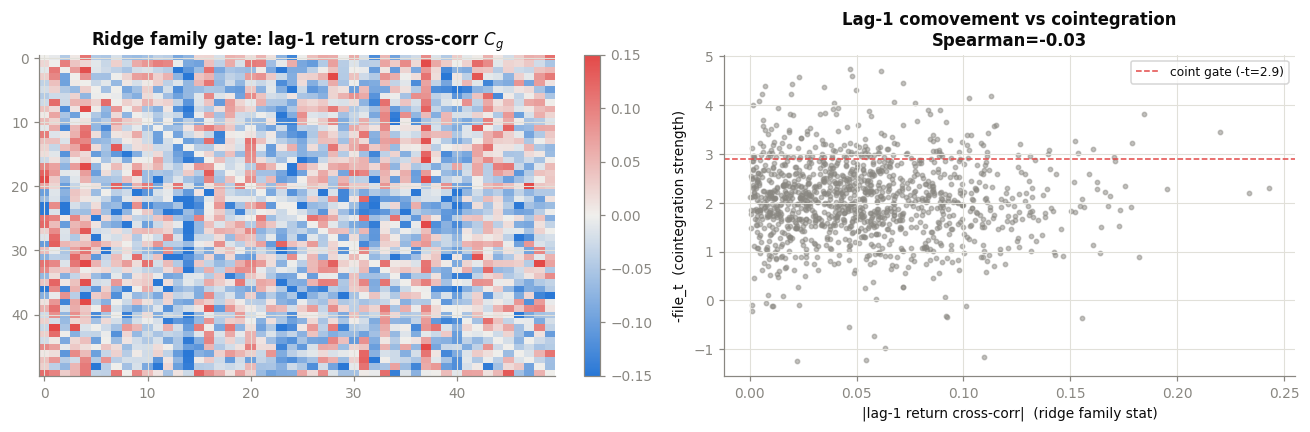

Near-zero correlation => the two gates measure different things.


: 

In [ ]:
r_all = np.diff(LP, axis=1)
R250 = r_all[1:, W_END-1-250:W_END-1].T
Xg = (R250 - R250.mean(0)) / (R250.std(0) + 1e-12)
Cg = (Xg[:-1].T @ Xg[1:]) / (len(R250) - 1); np.fill_diagonal(Cg, 0)
thr = 2.5/np.sqrt(len(R250)-1)
print(f"family gate: {int((np.abs(Cg)>thr).sum())} significant lag-1 links "
      f"(threshold |corr|>{thr:.3f}); RIDGE_GATE_N={TN.RIDGE_GATE_N}")

# relate lag-1 |cross-corr| to cointegration strength for the pairs we screened
lag1 = np.array([abs(Cg[TN._PI[k]-1, TN._PJ[k]-1]) for k in range(len(tfile))])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].imshow(Cg, cmap=DIV, vmin=-.15, vmax=.15, aspect="auto")
ax[0].set_title("Ridge family gate: lag-1 return cross-corr $C_g$"); fig.colorbar(im, ax=ax[0], fraction=.046)
ax[1].scatter(lag1, -tfile, s=8, color=MUTED, alpha=.5)
ax[1].axhline(-TN.PAIR_ADF_T, color=RED, ls="--", lw=1, label=f"coint gate (-t={-TN.PAIR_ADF_T})")
ax[1].set_xlabel("|lag-1 return cross-corr|  (ridge family stat)")
ax[1].set_ylabel("-file_t  (cointegration strength)")
ax[1].set_title(f"Lag-1 comovement vs cointegration\nSpearman={spearmanr(lag1,-tfile).correlation:.2f}")
ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()
print("Near-zero correlation => the two gates measure different things.")

## 9 · Synthesis — the evidence, for you to weigh

This is a summary of what the notebook measured, framed as findings and open
questions rather than recommendations.

**What the file computes (confirmed in §1–2).**
- The pairs sleeve is a textbook **Engle–Granger two-step**: OLS log-price hedge
  ratio (i on j, via the covariance) → **ADF(1) unit-root t-stat** on the
  residual. `_adf_tstat` matches `statsmodels.adfuller(maxlag=1)` to machine
  precision, and tracks the full EG statistic closely. So the machinery is sound;
  the only approximations are *fixed 1 lag* and *fixed regression direction*.

**On the gate value (§3).** The current threshold implies a specific
false-positive rate under the correct (estimated-β) null — read it off the
Monte-Carlo table. The plain-ADF intuition (−2.86 ≈ 5%) does **not** apply here;
the estimated hedge ratio moves the true 5% critical value more negative, so a
looser gate admits substantially more noise pairs. Question for you: what
false-positive rate do you actually want, given ~1,225 simultaneous tests?

**On agreement (§4).** The Spearman matrix and overlap bars show how much the
file's cheap test coincides with EG, ADF-AIC, and Johansen. Where they agree, the
signal is robust; where the file gates pairs the others reject, treat those as
low-confidence.

**On the design knobs (§5–6).**
- **Direction/β**: some verdicts flip between OLS i~j, OLS j~i, TLS, and Kalman —
  the file's fixed direction is a real modelling choice, not a neutral default.
- **Basis**: log vs raw changes the gated set; log is standard for ratio-style
  reversion.
- **Lookback**: shorter windows pass more pairs but overlap less with the 250-day
  set — i.e. short-window "cointegration" is less stable.
- **Lag order**: DF(0)/DF(1)/AIC mostly agree but can move borderline pairs.

**On persistence (§7).** The forward pass-rate of the day-500 pairs is the single
most decision-relevant number: it says how often a gated relationship is still
cointegrated later. Low persistence ⇒ the gate is catching transient structure.

**On the family gate (§8).** It is lag-1 return comovement, **not** cointegration,
and is nearly uncorrelated with cointegration strength — a separate mechanism.

**Open questions to settle for yourself.**
1. Is the current gate's false-positive rate acceptable, or should it be stricter?
2. Should the hedge ratio be symmetric (TLS) or dynamic (Kalman) rather than
   fixed-direction OLS?
3. Does forward persistence justify a 250-day lookback, or a different window?
4. Should selection require agreement across ≥2 tests (e.g. file gate **and**
   Johansen) instead of the single ADF(1) gate?